In [1]:
# Question 4.1
# Import the required libraries
import re
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import (
    CountVectorizer,
    ENGLISH_STOP_WORDS
)

from sklearn.decomposition import LatentDirichletAllocation
from IPython.display import display, FileLink


In [2]:
# Question 4.1
# Load the five research articles
files = [Path(f"../datasets/research_{i}.txt") for i in range(1, 6)]

records = []

for i, file in enumerate(files, start=1):

    content = file.read_text(encoding="utf-8-sig")

    records.append({
        "Article": f"Article {i}",
        "Filename": file.name,
        "Content": content,
        "Word_Count": len(content.split())
    })

# Create a DataFrame
df = pd.DataFrame(records)

print("Articles loaded:", len(df))

display(df[["Article", "Filename", "Word_Count"]])


Articles loaded: 5


,Article,Filename,Word_Count
0,Article 1,research_1.txt,5602
1,Article 2,research_2.txt,2416
2,Article 3,research_3.txt,3828
3,Article 4,research_4.txt,5922
4,Article 5,research_5.txt,4027


In [3]:
# QUestion 4.1
# Define stop words
stop_words = set(ENGLISH_STOP_WORDS) | {
    "et", "al", "http", "https", "www",
    "doi", "article", "articles", "journal",
    "vol", "volume", "pp", "page", "pages",
    "copyright", "publisher", "issn",
    "email", "university", "researcher", "researchers"
}

# Clean the research text
def clean_text(text):

    text = unicodedata.normalize("NFKC", text)

    text = re.sub(
        r"(?<=\w)-\s*\n\s*(?=\w)", "", text
    )

    text = re.sub(
        r"https?://\S+|www\.\S+|\S+@\S+",
        " ", text
    )

    words = re.findall(r"[a-z]{3,}", text.lower())

    return " ".join(
        word for word in words if word not in stop_words
    )

# Apply cleaning
df["Clean_Text"] = df["Content"].apply(clean_text)

# Divide cleaned documents into smaller sections
chunks = []
chunk_sources = []

for _, row in df.iterrows():

    words = row["Clean_Text"].split()

    for start in range(0, len(words), 120):

        section = words[start:start + 120]

        if len(section) >= 40:

            chunks.append(" ".join(section))
            chunk_sources.append(row["Article"])

print("Number of article sections:", len(chunks))

print("\nSections per article:")
print(pd.Series(chunk_sources).value_counts().sort_index())


Number of article sections: 93

Sections per article:
Article 1    24
Article 2    10
Article 3    17
Article 4    25
Article 5    17
Name: count, dtype: int64


In [4]:
# Question 4.1
# Convert research text into word counts
vectorizer = CountVectorizer(
    max_features=1600,
    min_df=2,
    max_df=0.95
)

doc_term_matrix = vectorizer.fit_transform(chunks)

# Train the LDA topic model
lda_model = LatentDirichletAllocation(
    n_components=4,
    random_state=42,
    learning_method="batch",
    max_iter=10
)

doc_topic_matrix = lda_model.fit_transform(
    doc_term_matrix
)

print("Document-term matrix shape:", doc_term_matrix.shape)
print("Number of topics:", lda_model.n_components)
print("LDA training completed successfully!")


Document-term matrix shape: (93, 1513)
Number of topics: 4
LDA training completed successfully!


In [5]:
# Question 4.1
# Display the top 10 words for each topic
terms = vectorizer.get_feature_names_out()

topic_words = {}

for topic_id, weights in enumerate(
    lda_model.components_, start=1
):

    top_ids = weights.argsort()[-10:][::-1]
    words = terms[top_ids].tolist()

    topic_words[f"Topic {topic_id}"] = words

    print(f"Topic {topic_id}:", ", ".join(words))

# Calculate average topic distribution for each article
article_topics = []
source_array = np.array(chunk_sources)

for article in df["Article"]:

    article_topics.append(
        doc_topic_matrix[
            source_array == article
        ].mean(axis=0)
    )

topic_df = pd.DataFrame(
    article_topics,
    index=df["Article"],
    columns=[f"Topic {i}" for i in range(1, 5)]
)

print("\nTopic distribution per article:")
display(topic_df.round(3))


Topic 1: research, methods, mixed, qualitative, quantitative, data, reflexivity, study, use, designs
Topic 2: research, data, triangulation, development, design, study, developmental, instructional, process, qualitative
Topic 3: research, social, theory, phenomena, test, assumptions, reality, consistent, methods, quantitative
Topic 4: alpha, cronbach, instrument, science, reliability, values, education, items, authors, used

Topic distribution per article:


,Topic 1,Topic 2,Topic 3,Topic 4
Article,,,,
Article 1,0.555,0.085,0.250,0.110
Article 2,0.948,0.046,0.003,0.003
Article 3,0.087,0.832,0.044,0.036
Article 4,0.002,0.003,0.047,0.948
Article 5,0.146,0.832,0.014,0.008


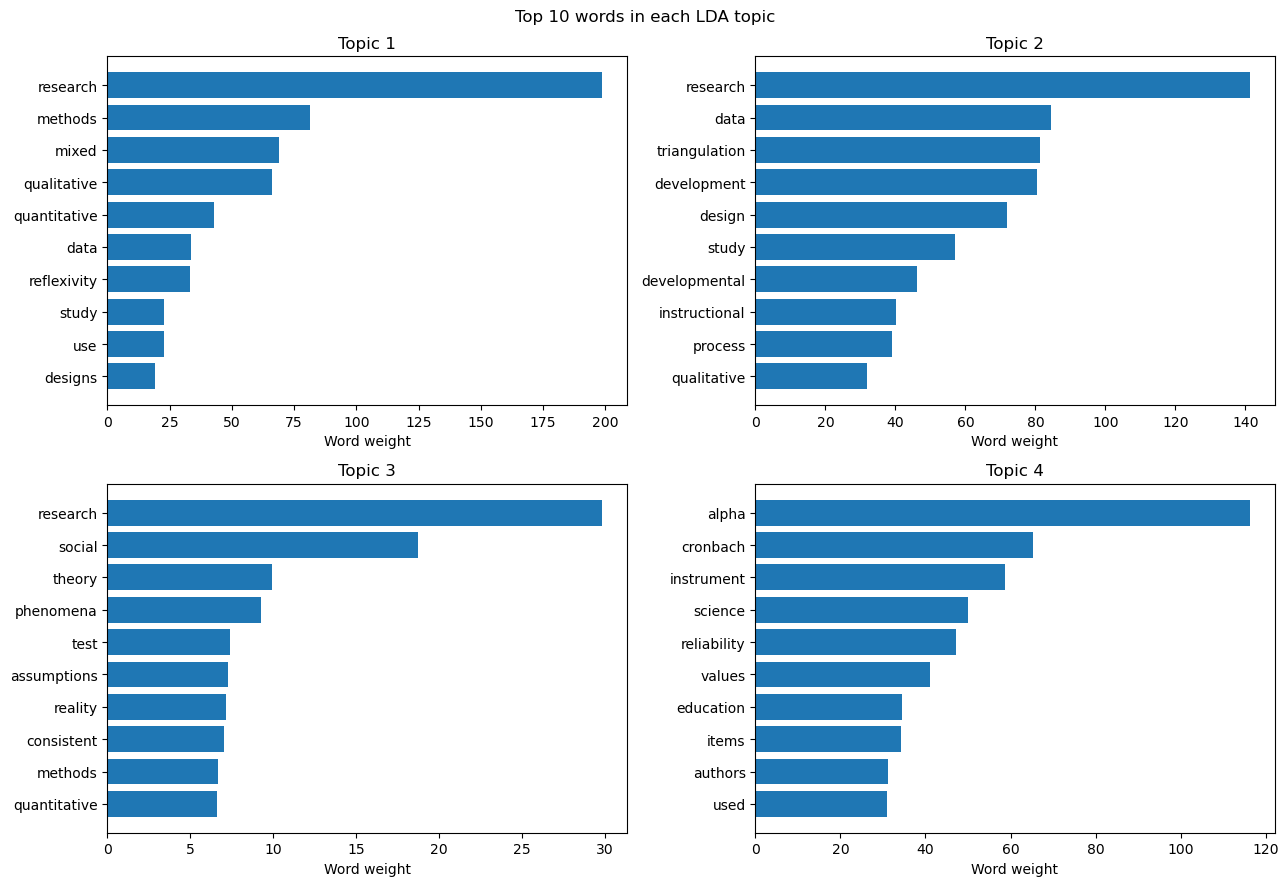

In [6]:
# Question 4.1
# Visualize the top words for each topic
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for idx, ax in enumerate(axes.flat):

    weights = lda_model.components_[idx]
    top_ids = weights.argsort()[-10:]

    ax.barh(
        terms[top_ids],
        weights[top_ids]
    )

    ax.set_title(f"Topic {idx + 1}")
    ax.set_xlabel("Word weight")

plt.suptitle("Top 10 words in each LDA topic")
plt.tight_layout()
plt.show()


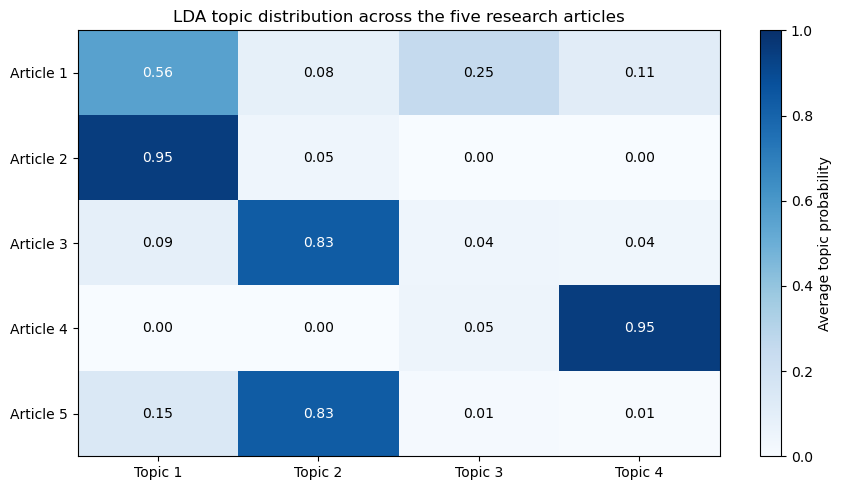

In [7]:
# Question 4.1
# Create a topic distribution heatmap
plt.figure(figsize=(9, 5))

plt.imshow(
    topic_df.values,
    cmap="Blues",
    vmin=0,
    vmax=1,
    aspect="auto"
)

plt.colorbar(label="Average topic probability")

plt.xticks(range(4), topic_df.columns)
plt.yticks(range(5), topic_df.index)

# Add values to the heatmap
for i in range(len(topic_df)):
    for j in range(4):

        value = topic_df.iloc[i, j]

        plt.text(
            j, i,
            f"{value:.2f}",
            ha="center",
            va="center",
            color="white" if value > 0.55 else "black"
        )

plt.title("LDA topic distribution across the five research articles")

plt.tight_layout()
plt.show()


In [8]:
# QUestion 4.2
# Install pyLDAvis
%pip install pyLDAvis


Note: you may need to restart the kernel to use updated packages.


In [9]:
# Question 4.2
# Import pyLDAvis
import pyLDAvis

# Prepare topic and word probabilities
term_counts = np.asarray(
    doc_term_matrix.sum(axis=0)
).ravel()

doc_lengths = np.asarray(
    doc_term_matrix.sum(axis=1)
).ravel()

topic_term = (
    lda_model.components_
    / lda_model.components_.sum(axis=1)[:, None]
)

# Create the interactive visualization
vis = pyLDAvis.prepare(
    topic_term_dists=topic_term,
    doc_topic_dists=doc_topic_matrix,
    doc_lengths=doc_lengths,
    vocab=vectorizer.get_feature_names_out(),
    term_frequency=term_counts,
    mds="pcoa",
    sort_topics=False,
    n_jobs=1
)

# Save the visualization as an HTML file
pyLDAvis.save_html(
    vis,
    "../outputs/lda_intertopic_map.html"
)

print("Interactive map saved successfully!")

# Display the map inside Jupyter Notebook
display(pyLDAvis.display(vis))

# Provide a link to the saved HTML file
display(FileLink("../outputs/lda_intertopic_map.html"))


Interactive map saved successfully!


C:\Users\wikus\ITNPA-Project 1-Online Campus-EDUV4818544\outputs\lda_intertopic_map.html